<a href="https://colab.research.google.com/github/gretelZavaleta/laberinto-inundaciones-ia/blob/main/laberinto_inundaciones_ia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Practica 2 - Cuando el camino más corto no es el mejor

## Simulación de rutas seguras ante inundaciones

**Objetivo:** Implementar y comparar algoritmos de búsqueda para encontrar rutas seguras desde una zona afectada hasta un refugio, considerando obstáculos y distintos niveles de riesgo.

**Integrantes:**
- Gretel Dairen Zavaleta Moctezuma
- Maria Tita Fregoso Arechiga
- Jesús Alexander Recaman Lara
- Henrry Misael Pech Pool


Módulo a cargo: representación del terreno, niveles de inundación, obstáculos y costos.

La posición de una celda se expresa como (fila, columna). El agente solo se moverá arriba, abajo, izquierda y derecha. El costo de cada movimiento se define por la casilla a la que entra. Este cuaderno no implementa todavía los algoritmos de búsqueda.



1. Definición de niveles

| Nivel | Significado | Costo de entrada |
|---|---|---|
| 0 | Segura | 1 |
| 1 | Inundación baja | 3 |
| 2 | Inundación media | 6 |
| 3 | Inundación alta | 10 |
| 4 | Zona bloqueada | No se puede transitar |

In [9]:
"""Modelo del terreno inundado para la simulación de rutas seguras.

Coordenadas: (fila, columna). Movimientos: arriba, abajo, izquierda y derecha.
El costo de una transición es el costo de ENTRAR a la casilla de destino.
"""

FILAS = 12
COLUMNAS = 16
INICIO = (6, 1)
REFUGIO = (6, 14)

# 0=segura, 1=riesgo bajo, 2=medio, 3=alto, 4=bloqueada.
COSTOS = {0: 1, 1: 3, 2: 6, 3: 10}
BLOQUEADO = 4




2. Construcción del terreno
Generamos una cuadrícula fija de 12 × 16. Se aplican regiones de riesgo de menor a mayor nivel para simular una zona inundada. Después agregamos obstáculos. Se reservan puntos transitables para el inicio y el refugio.

In [10]:
def crear_terreno():
    """Crea un escenario reproducible con zonas seguras y varios riesgos."""
    terreno = [[0 for _ in range(COLUMNAS)] for _ in range(FILAS)]

    # Orden importante: de zonas de menor a mayor riesgo.
    for fila in range(2, 10):
        for columna in range(2, 15):
            terreno[fila][columna] = 1

    for fila in range(3, 9):
        for columna in range(3, 14):
            terreno[fila][columna] = 2

    for fila in range(5, 8):
        for columna in range(6, 11):
            terreno[fila][columna] = 3

    # Celdas intransitables, incluso si antes tenían un nivel de riesgo.
    obstaculos = [(4, 4), (4, 5), (4, 6), (3, 8), (3, 9),
                  (7, 11), (8, 11), (8, 12)]
    for fila, columna in obstaculos:
        terreno[fila][columna] = BLOQUEADO

    # El inicio y el refugio deben ser transitables.
    terreno[INICIO[0]][INICIO[1]] = 0
    terreno[REFUGIO[0]][REFUGIO[1]] = 0
    return terreno

3. Funciones que usarán los algoritmos
- es_transitable evita salirse de la matriz y atravesar zonas bloqueadas.
- obtener_vecinos permite desplazamientos ortogonales, sin diagonales.
- costo_movimiento asigna el costo del nivel de inundación en la celda de destino.

In [11]:
def es_transitable(terreno, posicion):
    """Indica si la posición está dentro de la matriz y no está bloqueada."""
    fila, columna = posicion
    return (0 <= fila < len(terreno)
            and 0 <= columna < len(terreno[0])
            and terreno[fila][columna] != BLOQUEADO)


def obtener_vecinos(terreno, posicion):
    """Devuelve las posiciones vecinas transitables (sin diagonales)."""
    if not es_transitable(terreno, posicion):
        return []
    fila, columna = posicion
    movimientos = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    vecinos = []
    for df, dc in movimientos:
        vecino = (fila + df, columna + dc)
        if es_transitable(terreno, vecino):
            vecinos.append(vecino)
    return vecinos


def costo_movimiento(terreno, destino):
    """Retorna el costo de entrar en destino; rechaza celdas bloqueadas."""
    if not es_transitable(terreno, destino):
        raise ValueError(f"No se puede entrar en la celda {destino}.")
    return COSTOS[terreno[destino[0]][destino[1]]]

4. Modificar el escenario y verificar sus reglas
modificar_terreno devuelve una copia. Así podemos ejecutar los escenarios de prueba sin sobrescribir el terreno original. validar_escenario asegura que la matriz sea rectangular, use niveles conocidos y mantenga accesibles los puntos de inicio y refugio.

In [12]:
def modificar_terreno(terreno, posicion, nuevo_nivel):
    """Retorna una COPIA con un nivel actualizado sin modificar el original."""
    if nuevo_nivel not in (0, 1, 2, 3, BLOQUEADO):
        raise ValueError("El nivel debe ser 0, 1, 2, 3 o 4.")
    fila, columna = posicion
    if not (0 <= fila < len(terreno) and 0 <= columna < len(terreno[0])):
        raise ValueError("La posición está fuera del terreno.")
    nuevo_terreno = [renglon.copy() for renglon in terreno]
    nuevo_terreno[fila][columna] = nuevo_nivel
    return nuevo_terreno


def validar_escenario(terreno, inicio, refugio):
    """Verifica dimensiones, valores y que inicio/refugio sean transitables."""
    if not terreno or not terreno[0]:
        raise ValueError("El terreno no puede estar vacío.")
    columnas = len(terreno[0])
    if any(len(fila) != columnas for fila in terreno):
        raise ValueError("Todas las filas deben tener el mismo tamaño.")
    if any(nivel not in (0, 1, 2, 3, BLOQUEADO)
           for fila in terreno for nivel in fila):
        raise ValueError("El terreno contiene niveles desconocidos.")
    if not es_transitable(terreno, inicio):
        raise ValueError("El inicio no es transitable.")
    if not es_transitable(terreno, refugio):
        raise ValueError("El refugio no es transitable.")
    return True

5. Representación visual del mapa
Cada color distingue un nivel de inundación. El círculo azul señala el inicio y la estrella verde el refugio.

In [13]:
def visualizar_terreno(terreno, inicio=INICIO, refugio=REFUGIO, titulo="Mapa de inundación"):
    """Dibuja terreno, inicio y refugio usando matplotlib."""
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap
    from matplotlib.patches import Patch

    colores = ["#D7EED4", "#FBE4A8", "#F6A55C", "#D9594C", "#374151"]
    cmap = ListedColormap(colores)
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(terreno, cmap=cmap, vmin=-0.5, vmax=4.5, interpolation="nearest")
    filas, columnas = len(terreno), len(terreno[0])
    ax.set_xticks(range(columnas))
    ax.set_yticks(range(filas))
    ax.set_xticks([n - 0.5 for n in range(columnas + 1)], minor=True)
    ax.set_yticks([n - 0.5 for n in range(filas + 1)], minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.scatter(inicio[1], inicio[0], s=170, marker="o", c="#146FC4",
               edgecolors="white", linewidths=1.5, zorder=3)
    ax.scatter(refugio[1], refugio[0], s=250, marker="*", c="#138A48",
               edgecolors="white", linewidths=1, zorder=3)
    ax.set_xlabel("Columna")
    ax.set_ylabel("Fila")
    ax.set_title(titulo)
    leyenda = [Patch(facecolor=colores[i], label=texto) for i, texto in enumerate([
        "0 · Segura (costo 1)", "1 · Baja (costo 3)",
        "2 · Media (costo 6)", "3 · Alta (costo 10)",
        "4 · Bloqueada (sin paso)"])]
    ax.legend(handles=leyenda, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
    return fig, ax

Dimensiones: 12 × 16
Inicio: (6, 1) | Refugio: (6, 14)
Vecinos transitables del inicio: [(5, 1), (7, 1), (6, 0), (6, 2)]


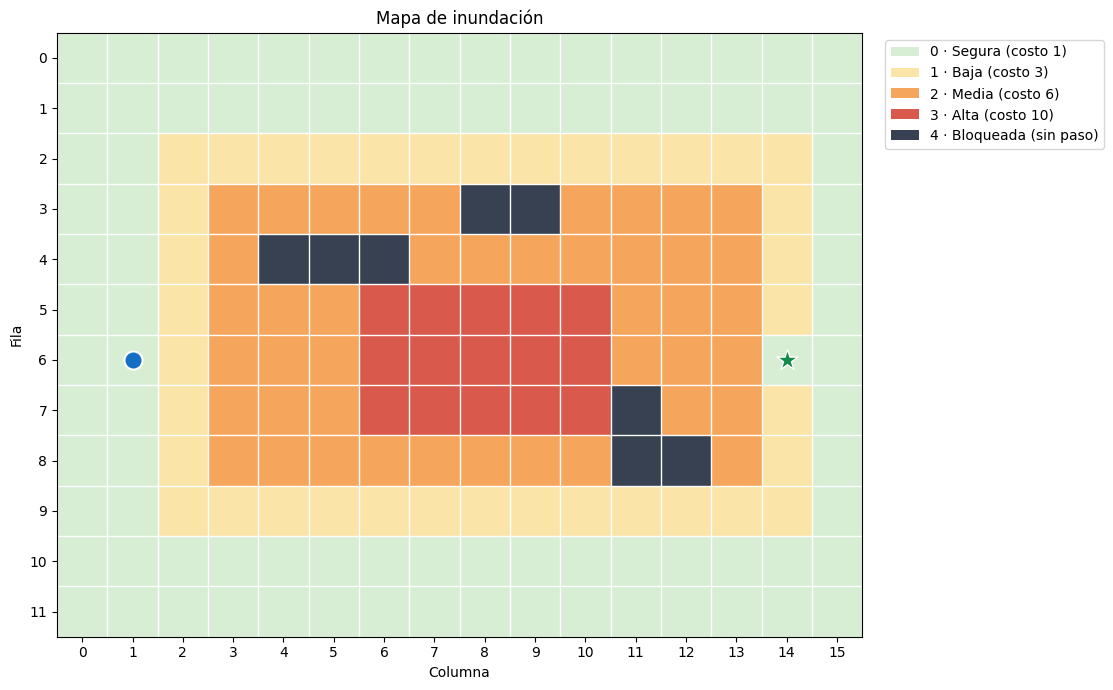

(<Figure size 1200x700 with 1 Axes>,
 <Axes: title={'center': 'Mapa de inundación'}, xlabel='Columna', ylabel='Fila'>)

In [14]:
terreno = crear_terreno()
validar_escenario(terreno, INICIO, REFUGIO)

print(f"Dimensiones: {len(terreno)} × {len(terreno[0])}")
print("Inicio:", INICIO, "| Refugio:", REFUGIO)
print("Vecinos transitables del inicio:", obtener_vecinos(terreno, INICIO))
visualizar_terreno(terreno, INICIO, REFUGIO)

6. Pruebas del módulo
Comprobamos que un obstáculo no sea vecino válido, que entrar en riesgo alto tenga el costo definido y que el cambio de una zona no modifique la matriz original. Esto todavía no sustituye las pruebas de rutas que deben hacer con los algoritmos.

Todas las comprobaciones básicas se completaron.


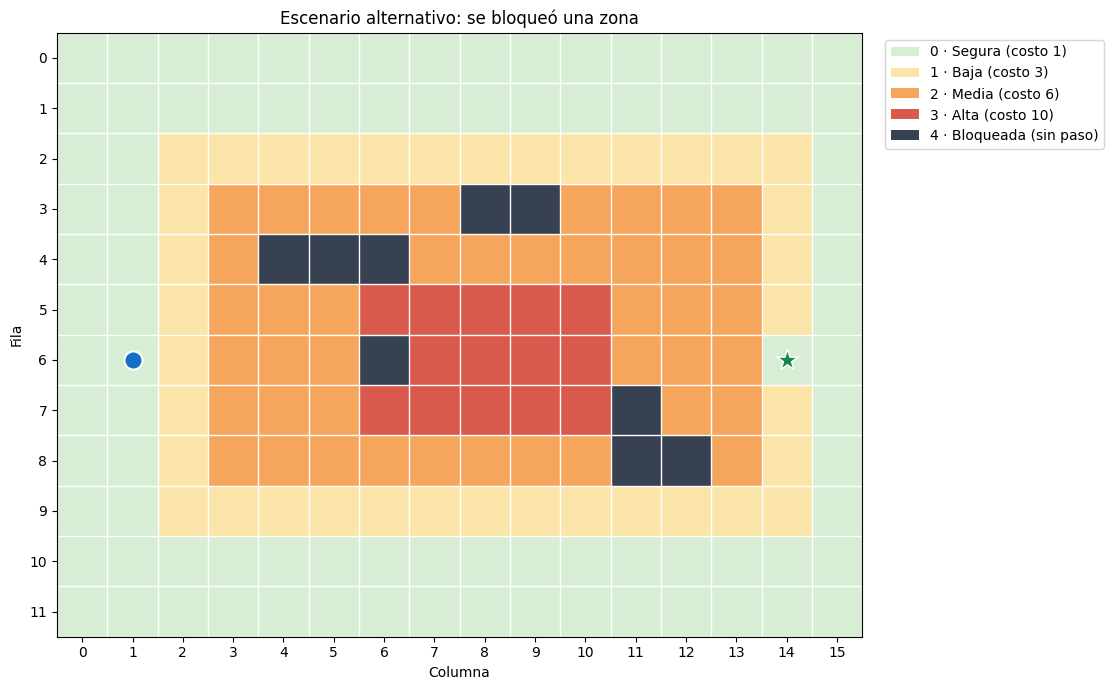

(<Figure size 1200x700 with 1 Axes>,
 <Axes: title={'center': 'Escenario alternativo: se bloqueó una zona'}, xlabel='Columna', ylabel='Fila'>)

In [15]:
assert terreno[6][6] == 3
assert costo_movimiento(terreno, (6, 6)) == 10
assert terreno[4][4] == 4
assert (4, 4) not in obtener_vecinos(terreno, (4, 3))

terreno_bloqueado = modificar_terreno(terreno, (6, 6), 4)
assert terreno_bloqueado[6][6] == 4
assert terreno[6][6] == 3  # original intacto
validar_escenario(terreno_bloqueado, INICIO, REFUGIO)

print("Todas las comprobaciones básicas se completaron.")
visualizar_terreno(terreno_bloqueado, INICIO, REFUGIO,
                    "Escenario alternativo: se bloqueó una zona")

# PARTE 2 · BFS y Dijkstra
**Módulo a cargo:** algoritmos de búsqueda BFS y Dijkstra.

Ambos algoritmos reciben el terreno de la Parte 1 y devuelven un diccionario con la ruta, el costo total, los pasos, los **nodos expandidos** (medida del trabajo realizado) y el nivel máximo de inundación que atraviesa la ruta.

| Algoritmo | Qué minimiza | ¿Considera el riesgo? |
|---|---|---|
| BFS | Número de pasos | No |
| Dijkstra | Costo total (pasos + riesgo) | Sí |

**Decisión de diseño:** el parámetro `peso_riesgo` controla cuánto pesa el riesgo. Con `peso_riesgo = 1` el costo de cada celda es el definido en la Parte 1 (1, 3, 6, 10). Con `peso_riesgo = 0` todos los pasos cuestan 1 y se ignora el riesgo.

In [16]:
import heapq
import time
from collections import deque

INF = float("inf")


def costo_paso(terreno, destino, peso_riesgo=1.0):
    """Costo de entrar a 'destino'. Con peso_riesgo=1 es exactamente COSTOS[nivel];
    con peso_riesgo=0 todos los pasos cuestan 1 (se ignora el riesgo)."""
    return 1.0 + peso_riesgo * (costo_movimiento(terreno, destino) - 1)


def costo_ruta(terreno, ruta, peso_riesgo=1.0):
    """Suma el costo de entrada de cada celda de la ruta (menos la inicial)."""
    return sum(costo_paso(terreno, n, peso_riesgo) for n in ruta[1:])


def reconstruir_ruta(padres, fin):
    ruta, nodo = [], fin
    while nodo is not None:
        ruta.append(nodo)
        nodo = padres[nodo]
    return ruta[::-1]


def _resultado(nombre, terreno, ruta, expandidos, t0, peso_riesgo):
    return {
        "algoritmo": nombre,
        "ruta": ruta,
        "costo": costo_ruta(terreno, ruta, peso_riesgo) if ruta else None,
        "pasos": len(ruta) - 1 if ruta else None,
        "expandidos": expandidos,
        "tiempo_ms": (time.perf_counter() - t0) * 1000,
        "nivel_max": max(terreno[f][c] for f, c in ruta) if ruta else None,
    }


def _extremos_validos(terreno, inicio, refugio):
    return es_transitable(terreno, inicio) and es_transitable(terreno, refugio)


def bfs(terreno, inicio, refugio, peso_riesgo=1.0):
    """Ruta con menor número de pasos. NO considera el riesgo para decidir."""
    t0 = time.perf_counter()
    if not _extremos_validos(terreno, inicio, refugio):
        return _resultado("BFS", terreno, None, 0, t0, peso_riesgo)
    padres = {inicio: None}
    cola = deque([inicio])
    expandidos = 0
    while cola:
        actual = cola.popleft()
        expandidos += 1
        if actual == refugio:
            ruta = reconstruir_ruta(padres, actual)
            return _resultado("BFS", terreno, ruta, expandidos, t0, peso_riesgo)
        for vecino in obtener_vecinos(terreno, actual):
            if vecino not in padres:
                padres[vecino] = actual
                cola.append(vecino)
    return _resultado("BFS", terreno, None, expandidos, t0, peso_riesgo)

## Dijkstra
Dijkstra usa una **cola de prioridad** ordenada por el costo acumulado. Siempre expande primero la celda más barata de alcanzar, así que la primera vez que llega al refugio ya tiene la ruta de menor costo total. Por eso puede preferir un rodeo largo por zonas seguras en lugar de cruzar agua profunda.

Si el refugio no se puede alcanzar, devuelve `ruta = None` en lugar de inventar un camino.


In [17]:
def dijkstra(terreno, inicio, refugio, peso_riesgo=1.0):
    """Ruta de menor costo total (pasos + riesgo)."""
    t0 = time.perf_counter()
    if peso_riesgo < 0:
        raise ValueError("peso_riesgo debe ser >= 0")
    if not _extremos_validos(terreno, inicio, refugio):
        return _resultado("Dijkstra", terreno, None, 0, t0, peso_riesgo)
    dist = {inicio: 0.0}
    padres = {inicio: None}
    cerrados = set()
    desempate = 0
    heap = [(0.0, desempate, inicio)]
    expandidos = 0
    while heap:
        d, _, actual = heapq.heappop(heap)
        if actual in cerrados:
            continue
        cerrados.add(actual)
        expandidos += 1
        if actual == refugio:
            ruta = reconstruir_ruta(padres, actual)
            return _resultado("Dijkstra", terreno, ruta, expandidos, t0, peso_riesgo)
        for vecino in obtener_vecinos(terreno, actual):
            if vecino in cerrados:
                continue
            nuevo = d + costo_paso(terreno, vecino, peso_riesgo)
            if nuevo < dist.get(vecino, INF):
                dist[vecino] = nuevo
                padres[vecino] = actual
                desempate += 1
                heapq.heappush(heap, (nuevo, desempate, vecino))
    return _resultado("Dijkstra", terreno, None, expandidos, t0, peso_riesgo)


## Comprobación de la Parte 2
Ejecutamos BFS y Dijkstra sobre el terreno de 12 × 16 y probamos el caso en que el refugio queda rodeado de celdas bloqueadas.



In [18]:
b = bfs(terreno, INICIO, REFUGIO)
d = dijkstra(terreno, INICIO, REFUGIO)
print("BFS     :", b["pasos"], "pasos | costo", b["costo"], "| expandidos", b["expandidos"])
print("Dijkstra:", d["pasos"], "pasos | costo", d["costo"], "| expandidos", d["expandidos"])

# Refugio inaccesible: se bloquean sus vecinos
t_aislado = terreno
for v in obtener_vecinos(terreno, REFUGIO):
    t_aislado = modificar_terreno(t_aislado, v, BLOQUEADO)
assert bfs(t_aislado, INICIO, REFUGIO)["ruta"] is None
assert dijkstra(t_aislado, INICIO, REFUGIO)["ruta"] is None
print("Refugio aislado: ambos algoritmos reportan 'sin ruta'.")



BFS     : 13 pasos | costo 90.0 | expandidos 136
Dijkstra: 23 pasos | costo 23.0 | expandidos 146
Refugio aislado: ambos algoritmos reportan 'sin ruta'.


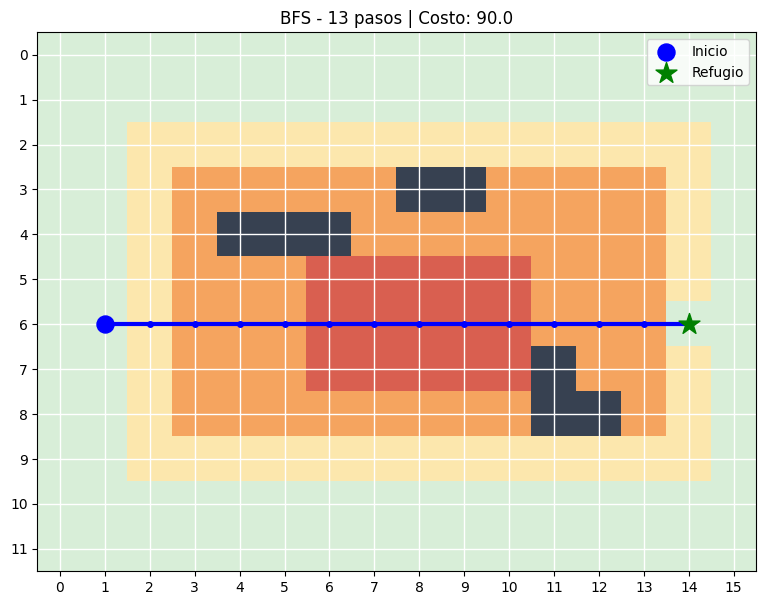

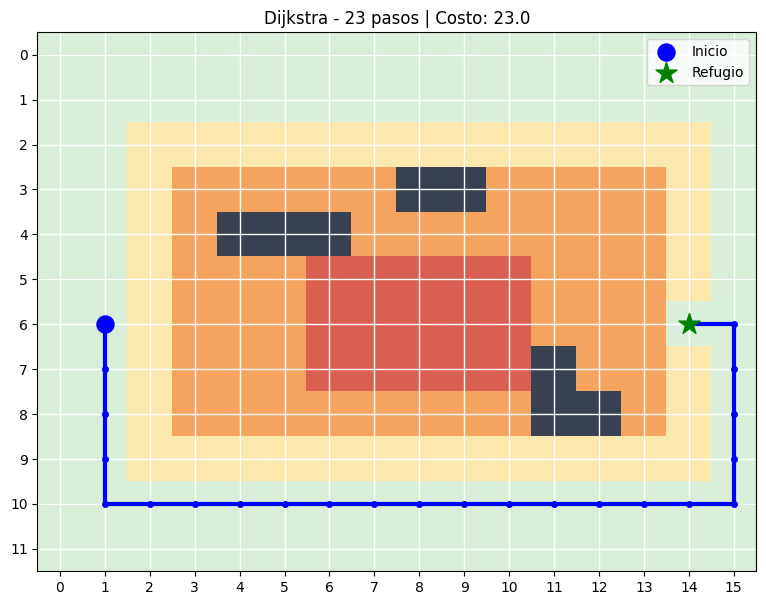

In [21]:

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def visualizar_ruta(terreno, resultado, titulo):
    ruta = resultado["ruta"]

    colores = ListedColormap([
        "#D8EED8",  # Nivel 0
        "#FCE7AD",  # Nivel 1
        "#F5A45F",  # Nivel 2
        "#D95F50",  # Nivel 3
        "#374151"   # Bloqueado
    ])

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(terreno, cmap=colores, vmin=0, vmax=4)

    if ruta:
        filas = [pos[0] for pos in ruta]
        columnas = [pos[1] for pos in ruta]

        ax.plot(columnas, filas, color="blue",
                linewidth=3, marker="o", markersize=4)

    ax.scatter(INICIO[1], INICIO[0],
               color="blue", s=150, label="Inicio", zorder=5)

    ax.scatter(REFUGIO[1], REFUGIO[0],
               color="green", marker="*", s=250,
               label="Refugio", zorder=5)

    ax.set_xticks(range(len(terreno[0])))
    ax.set_yticks(range(len(terreno)))
    ax.grid(color="white", linewidth=1)
    ax.set_title(titulo)
    ax.legend()
    plt.show()


# Visualizar BFS
visualizar_ruta(
    terreno,
    b,
    f"BFS - {b['pasos']} pasos | Costo: {b['costo']}"
)

# Visualizar Dijkstra
visualizar_ruta(
    terreno,
    d,
    f"Dijkstra - {d['pasos']} pasos | Costo: {d['costo']}"
)



### Resultados observados
| Algoritmo | Pasos | Costo | Nodos expandidos |
|---|---|---|---|
| BFS | 13 | 90 | 136 |
| Dijkstra | 23 | 23 | 146 |

BFS encuentra la ruta más corta (13 pasos), pero atraviesa la zona de inundación alta y por eso su costo es 90. Dijkstra da un rodeo de 23 pasos por zonas seguras y su costo es solo 23. **La ruta más corta no es la más conveniente.**

Dijkstra expandió más nodos que BFS en este escenario (146 contra 136) porque explora por costo y no por cercanía. Cuando el refugio queda rodeado de celdas bloqueadas, ambos devuelven "sin ruta".


### Pruebas experimentales: detección de errores y datos ficticios

En esta sección se realizan pruebas controladas para comprobar cómo responde el sistema ante situaciones incorrectas, como intentar atravesar una zona bloqueada o utilizar un nivel de inundación inexistente.

También se incluyen datos ficticios y mensajes de humor para ejemplificar resultados imposibles y demostrar su detección. Estos valores no representan mediciones reales ni modifican el funcionamiento de los algoritmos BFS y Dijkstra.

El objetivo es verificar que el sistema identifique condiciones inválidas y mantenga la integridad de los resultados obtenidos durante la búsqueda de rutas.

In [19]:

# ============================================================
# PRUEBAS EXPERIMENTALES: ERRORES INTENCIONALES Y DATOS FICTICIOS
# Modulo 2 - BFS y Dijkstra
# Estas pruebas no modifican los algoritmos originales.
# ============================================================

print("REPORTE EXPERIMENTAL DE INUNDACIONES")
print("=" * 60)

# ERROR 1: Intentar atravesar una zona bloqueada
try:
    costo_movimiento(terreno, (4, 4))
except ValueError:
    print("ERROR 1: Eso no es una carretera, es una piscina.")
    print("El sistema detecto correctamente la zona bloqueada.\n")

# ERROR 2: Utilizar un nivel de inundacion inexistente
try:
    modificar_terreno(terreno, (6, 6), 99)
except ValueError:
    print("ERROR 2: Nivel 99. Buscamos un refugio o la Atlantida?")
    print("El sistema rechazo el nivel de inundacion invalido.\n")


# ============================================================
# DATOS FICTICIOS DEL SIMULADOR
# ============================================================

print("\nDATOS FICTICIOS DEL SIMULADOR")
print("-" * 60)

datos_ficticios = {
    "Nivel de inundacion": 999,
    "Profundidad del agua": "300 metros",
    "Velocidad del agente": "500 km/h",
    "Nodos explorados": -25,
    "Costo de la ruta": -100,
    "Probabilidad de encontrar sirenas": "98%",
    "Tiempo estimado de rescate": "3 siglos"
}

for dato, valor in datos_ficticios.items():
    print(f"{dato}: {valor}")


# ============================================================
# DETECCION DE DATOS IMPOSIBLES
# ============================================================

print("\nDETECTANDO DATOS IMPOSIBLES...")

if datos_ficticios["Nodos explorados"] < 0:
    print("ERROR: Nodos negativos. El algoritmo exploro otra dimension.")

if datos_ficticios["Costo de la ruta"] < 0:
    print("ERROR: Costo negativo. Ahora nos pagan por caminar?")

if datos_ficticios["Nivel de inundacion"] > 4:
    print("ERROR: Inundacion fuera de escala. Hasta los peces pidieron refugio.")

print("\nLos datos anteriores son ficticios y no representan mediciones reales.")


# ============================================================
# MENSAJES DE HUMOR BASADOS EN LOS RESULTADOS
# ============================================================

def mensaje_broma(texto):
    """Muestra un mensaje de humor sin modificar los resultados."""
    print("=" * 60)
    print("BROMA (no es una medicion):", texto)
    print("=" * 60)


# Obtener resultados reales
b = bfs(terreno, INICIO, REFUGIO)
d = dijkstra(terreno, INICIO, REFUGIO)

print("\nERROR: El algoritmo se quedo sin cafe.")
print("Calculo la ruta en 0.0001 ms... segun sus suenos.")
print("Este tiempo es ficticio, no una medicion real.\n")

if b["ruta"] is not None and d["ruta"] is not None:
    mensaje_broma(
        f"BFS dice: Cruzo el agua nivel {b['nivel_max']}, "
        "que puede salir mal?"
    )

    diferencia = d["pasos"] - b["pasos"]

    mensaje_broma(
        f"Dijkstra dice: Yo mejor doy {diferencia} "
        "pasos de mas y evito la inundacion."
    )

print("\nERROR: No se encontro el refugio.")
print("Se fue de vacaciones a la playa.")
print("Broma sobre el escenario de refugio aislado.\n")

print("=" * 60)
print("PRUEBAS EXPERIMENTALES FINALIZADAS")
print("BFS y Dijkstra no fueron modificados.")
print("Se provocaron y detectaron dos errores controlados.")
print("Los mensajes de humor no afectan los resultados reales.")


REPORTE EXPERIMENTAL DE INUNDACIONES
ERROR 1: Eso no es una carretera, es una piscina.
El sistema detecto correctamente la zona bloqueada.

ERROR 2: Nivel 99. Buscamos un refugio o la Atlantida?
El sistema rechazo el nivel de inundacion invalido.


DATOS FICTICIOS DEL SIMULADOR
------------------------------------------------------------
Nivel de inundacion: 999
Profundidad del agua: 300 metros
Velocidad del agente: 500 km/h
Nodos explorados: -25
Costo de la ruta: -100
Probabilidad de encontrar sirenas: 98%
Tiempo estimado de rescate: 3 siglos

DETECTANDO DATOS IMPOSIBLES...
ERROR: Nodos negativos. El algoritmo exploro otra dimension.
ERROR: Costo negativo. Ahora nos pagan por caminar?
ERROR: Inundacion fuera de escala. Hasta los peces pidieron refugio.

Los datos anteriores son ficticios y no representan mediciones reales.

ERROR: El algoritmo se quedo sin cafe.
Calculo la ruta en 0.0001 ms... segun sus suenos.
Este tiempo es ficticio, no una medicion real.

BROMA (no es una medicion)

ERROR 1: INTENTO DE ATRAVESAR UNA CELDA BLOQUEADA


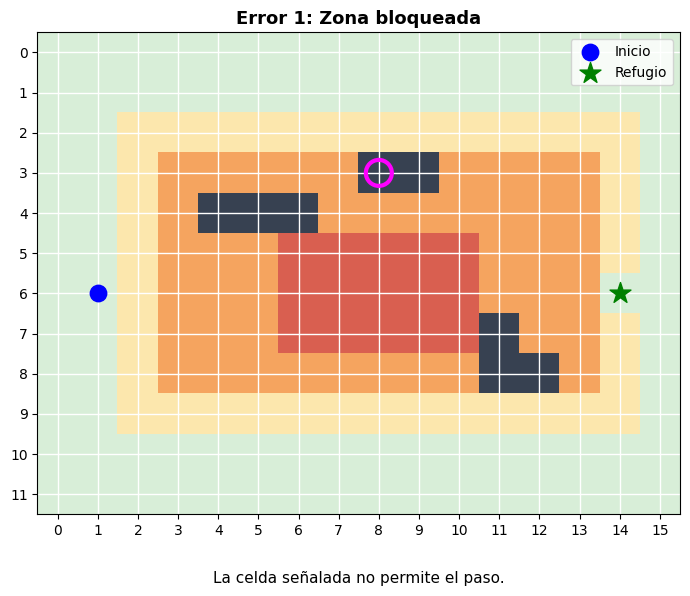

Resultado: el sistema rechazo la celda bloqueada.

ERROR 2: NIVEL DE INUNDACION INVALIDO


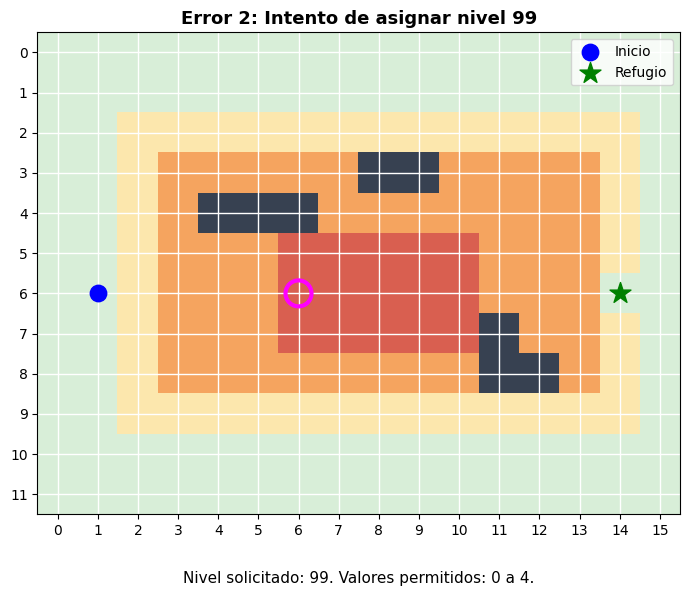

Resultado: el sistema rechazo el nivel 99.

ERROR 3: REFUGIO INACCESIBLE


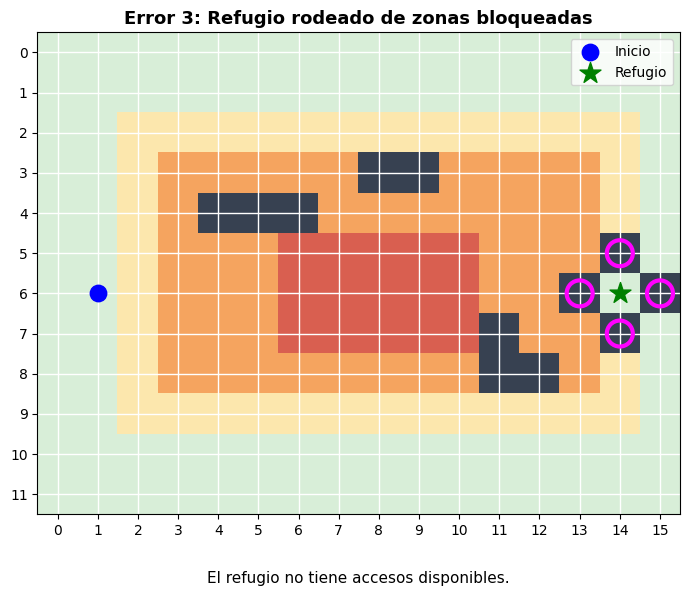

BFS: Sin ruta
Dijkstra: Sin ruta

Las pruebas de visualizacion finalizaron correctamente.
El terreno original y los algoritmos no fueron modificados.


In [22]:

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from copy import deepcopy

# ============================================================
# VISUALIZACION DE ERRORES EN EL LABERINTO
# ============================================================

colores = ListedColormap([
    "#D8EED8",  # Nivel 0: seguro
    "#FCE7AD",  # Nivel 1: bajo
    "#F5A45F",  # Nivel 2: medio
    "#D95F50",  # Nivel 3: alto
    "#374151"   # Nivel 4: bloqueado
])


def mostrar_escenario(mapa, titulo, destacar=None, mensaje=None):
    fig, ax = plt.subplots(figsize=(11, 6))

    ax.imshow(mapa, cmap=colores, vmin=0, vmax=4)

    # Inicio y refugio
    ax.scatter(INICIO[1], INICIO[0],
               color="blue", s=140, label="Inicio", zorder=5)

    ax.scatter(REFUGIO[1], REFUGIO[0],
               color="green", marker="*", s=250,
               label="Refugio", zorder=5)

    # Destacar celdas relacionadas con el error
    if destacar:
        for fila, columna in destacar:
            ax.scatter(columna, fila, facecolors="none",
                       edgecolors="magenta", s=350,
                       linewidths=3, zorder=6)

    ax.set_xticks(range(len(mapa[0])))
    ax.set_yticks(range(len(mapa)))
    ax.grid(color="white", linewidth=1)

    ax.set_title(titulo, fontsize=13, fontweight="bold")
    ax.legend(loc="upper right")

    if mensaje:
        fig.text(0.5, 0.02, mensaje,
                 ha="center", fontsize=11)

    plt.tight_layout(rect=[0, 0.07, 1, 1])
    plt.show()


# ============================================================
# ERROR 1: CELDA BLOQUEADA
# ============================================================

print("ERROR 1: INTENTO DE ATRAVESAR UNA CELDA BLOQUEADA")

bloqueadas = [
    (f, c)
    for f, fila in enumerate(terreno)
    for c, nivel in enumerate(fila)
    if nivel == BLOQUEADO
]

if bloqueadas:
    celda_error = bloqueadas[0]

    mostrar_escenario(
        terreno,
        "Error 1: Zona bloqueada",
        destacar=[celda_error],
        mensaje="La celda señalada no permite el paso."
    )

    try:
        costo_movimiento(terreno, celda_error)
    except ValueError:
        print("Resultado: el sistema rechazo la celda bloqueada.")
else:
    print("No se encontraron celdas bloqueadas.")


# ============================================================
# ERROR 2: NIVEL DE INUNDACION INVALIDO
# ============================================================

print("\nERROR 2: NIVEL DE INUNDACION INVALIDO")

celda_invalida = (6, 6)

mostrar_escenario(
    terreno,
    "Error 2: Intento de asignar nivel 99",
    destacar=[celda_invalida],
    mensaje="Nivel solicitado: 99. Valores permitidos: 0 a 4."
)

try:
    modificar_terreno(terreno, celda_invalida, 99)
except ValueError:
    print("Resultado: el sistema rechazo el nivel 99.")


# ============================================================
# ERROR 3: REFUGIO INACCESIBLE
# ============================================================

print("\nERROR 3: REFUGIO INACCESIBLE")

t_aislado = deepcopy(terreno)

# Bloquear las cuatro posiciones adyacentes al refugio
vecinos_refugio = [
    (REFUGIO[0] - 1, REFUGIO[1]),
    (REFUGIO[0] + 1, REFUGIO[1]),
    (REFUGIO[0], REFUGIO[1] - 1),
    (REFUGIO[0], REFUGIO[1] + 1)
]

for f, c in vecinos_refugio:
    if 0 <= f < len(t_aislado) and 0 <= c < len(t_aislado[0]):
        t_aislado[f][c] = BLOQUEADO

mostrar_escenario(
    t_aislado,
    "Error 3: Refugio rodeado de zonas bloqueadas",
    destacar=[
        (f, c) for f, c in vecinos_refugio
        if 0 <= f < len(t_aislado)
        and 0 <= c < len(t_aislado[0])
    ],
    mensaje="El refugio no tiene accesos disponibles."
)

resultado_bfs = bfs(t_aislado, INICIO, REFUGIO)
resultado_dijkstra = dijkstra(t_aislado, INICIO, REFUGIO)

print("BFS:", "Sin ruta" if resultado_bfs["ruta"] is None else "Ruta encontrada")
print("Dijkstra:", "Sin ruta" if resultado_dijkstra["ruta"] is None else "Ruta encontrada")

assert resultado_bfs["ruta"] is None
assert resultado_dijkstra["ruta"] is None

print("\nLas pruebas de visualizacion finalizaron correctamente.")
print("El terreno original y los algoritmos no fueron modificados.")
